# GPS code observations — each modeled error, measured in metres

**Station:** DYNG · **Satellite:** G21 · **Date:** 2024-01-01 · **Observables:** RINEX 3 code (no carrier phase).

Instead of solving for station coordinates immediately, we isolate the size,
sign, elevation dependence and effect of **each model used in**
[`beta/gps_code_positioning.ipynb`](beta/gps_code_positioning.ipynb).

The positioning notebook implements the observation equation

$$
\underbrace{P_{IF}^{\mathrm{corr}}+c\,\delta t_s}_{\mathrm{corrected\ observation}}
=\underbrace{\|\mathbf r_s(t_{tx})-(\mathbf r_{marker}+\mathbf d_{ARP}
+\mathbf d_{SET})\|}_{\mathrm{emission\ time\ geometry}}
+\underbrace{c\,\delta t_r}_{\mathrm{estimated}}
+\Delta\rho_{Sag}+\Delta\rho_{rel}
+\underbrace{ZHD\,m_h+ZWD(t)\,m_w}_{\mathrm{neutral\ atmosphere}}+\epsilon.
$$

Here $P_{IF}^{\mathrm{corr}}$ includes the code-specific **OSB** and receiver/satellite
**antenna** corrections. The satellite clock is a known SP3 correction;
the **receiver clock is an unknown to estimate**. $ZHD$ comes from VMF3,
but the final positioning solution **estimates piecewise-linear ZWD**.

Related shorter lessons:
[light travel time](../light_travel_time/signal_travel_time_intro.ipynb) ·
[antenna ANTEX](../antex_intro/gnss_antex_antenna_intro.ipynb) ·
[code biases](../gnss_bias_intro/gnss_bias_sinex_intro.ipynb) ·
[ionosphere](../atmosphere/gnss_ionosphere_intro.ipynb) ·
[troposphere](../atmosphere/gnss_tropospheric_delay_intro.ipynb) ·
[SINEX coordinates](../sinex_intro/gnss_sinex_coordinates_intro.ipynb).


## 1. Data and model setup

The SP3 orbit/clock, RINEX code observations, daily satellite OSBs, ANTEX
calibration and site-wise VMF3 file are the **same products** used in GPS
code positioning. No additional files are needed.

We sample one satellite every three minutes, staying a **3° elevation cutoff** aangle.


In [2]:
from os.path import join
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

from dsoclasses.gnss import systems as gs
from dsoclasses.gnss import algorithms as alg
from dsoclasses.gnss.atx import Atx
from dsoclasses.gnss.biasx import Bsinex
from dsoclasses.geodesy import transformations
from dsoclasses.geodesy.earth_models import solid_earth_tide_xyz
from dsoclasses.orbits.interpolator import Sp3Interpolator
from dsoclasses.rinex.gnss.rinex import GnssRinex, fetch
from dsoclasses.time.astropy_time import to_astropy_time
from dsoclasses.troposphere.vmf3 import SiteVmf3

data_path = "../../data"
rinex_path = join(data_path, "DYNG00GRC_R_20240010000_01D_30S_MO.rnx")
sp3_path = join(data_path, "COD0MGXFIN_20240010000_01D_05M_ORB.SP3")
bias_path = join(data_path, "COD0MGXFIN_20240010000_01D_01D_OSB.BIA")
antex_path = join(data_path, "igs20.atx")
vmf3_path = join(data_path, "y2024.vmf3_g")

SAT = "G21"
CODE1 = ('C1W', 'C1C', 'C1X', 'C1L')
CODE2 = ('C2W', 'C2C', 'C2D', 'C2P', 'C2X', 'C2S', 'C2L')
EVERY_SEC = 180
ELEVATION_CUTOFF_DEG = 3.0
MAX_SAMPLES = 250  # None means every suitable epoch (slower, not more accurate).

# GPS frequencies here are MHz; only squared-frequency ratios are needed.
f1, f2 = gs.GPS_L1_FREQ, gs.GPS_L2_FREQ
a1 = f1*f1/(f1*f1-f2*f2)
a2 = -f2*f2/(f1*f1-f2*f2)
print(f'P_IF = ({a1:.6f}) * P1 + ({a2:+.6f}) * P2')
# assert np.isclose(a1+a2, 1.0)
# assert np.isclose(a1/f1**2+a2/f2**2, 0., atol=1e-15)


P_IF = (2.545728) * P1 + (-1.545728) * P2


In [8]:
# Create a GnssRinex instance using the RINEX filename
rnx = GnssRinex(rinex_path)

# Create an Sp3Interpolator instance
intrp = Sp3Interpolator.from_sp3(sp3_path, ['G'], interval_in_sec=2400,min_data_pts=8, stencil_pts=8, itype='Barycentric')

# Check that time-scales are consistent
rinex_scale = (rnx.time_sys or '').strip().upper()
sp3_scale = intrp.time_system().strip().upper()
print('RINEX/SP3 time labels:', rinex_scale, '/', sp3_scale)
if rinex_scale != sp3_scale:
    raise ValueError('RINEX/SP3 time scales differ; convert explicitly before this lesson')

# get marker approx. cartesian position, transform to geodetic, get 
# its name and make sure we also have its eccentricity
marker_xyz = np.asarray(rnx.approx_cartesian(), dtype=float)
lat, lon, height_m = transformations.car2ell(*marker_xyz)
site = rnx.marker_name[:4].upper()
if not all(hasattr(rnx, s) for s in ('de', 'dn', 'dh')):
    raise ValueError('RINEX antenna H/E/N eccentricities are required')

# geodetic2lvlh transforms EAST-NORTH-UP (ENU) -> ECEF.
# Marker to ARP as recorded in the RINEX file (cartesian)
offset_arp = transformations.geodetic2lvlh(lat, lon) @ np.array([rnx.de, rnx.dn, rnx.dh], dtype=float)

# create instances for SiteVmf3 (tropo model/corrections) ...
vmf = SiteVmf3(vmf3_path, site_list=[site])
# ... Bsinex (SINEX BIAS) for hardware biases ...
osb = Bsinex(bias_path)
# ... Atx for receiver/transmitter PCO and PCV corrections ...
antex = Atx(antex_path)
# ... and extract GPS L1/L2 PCO values for receiver antenna ...
rx_ant = antex.get_noazi(rnx.antenna_type, ['G01', 'G02'])

print('Station:', rnx.marker_name, '| antenna:', rnx.antenna_type)
print('RINEX marker XYZ [m]:', marker_xyz)
print('Marker -> ARP vector [m]:', offset_arp)
print('Receiver ANTEX PCO [N,E,U] G01 [m]:', rx_ant.pco('G01'))
print('First epoch in UTC:', to_astropy_time(rnx.time_first_obs, rinex_scale).utc.isot)


RINEX/SP3 time labels: GPS / GPS
Station: DYNG | antenna: TRM59800.00     NONE
RINEX marker XYZ [m]: [4595218.5637 2039433.4368 3912624.7622]
Marker -> ARP vector [m]: [1.45192864 0.64438977 1.24458388]
Receiver ANTEX PCO [N,E,U] G01 [m]: [0.00065 0.00135 0.08935]
First epoch in UTC: 2023-12-31T23:59:42.000


/tmp/ipykernel_1254906/3697665264.py:27: RuntimeWarning: Skipped 2 VMF3 record(s) with nonpositive wet mapping coefficient a_w in ../../data/y2024.vmf3_g; first: DYNG at 2024-02-12 06:00:00 (line 100906, a_w=-1.5e-06). Interpolation across missing six-hour records is not permitted.
  vmf = SiteVmf3(vmf3_path, site_list=[site])


## 2. Form one table of real observations

For each selected epoch we compute the **original** L1/L2 pseudoranges,
the corrections, and the simple modeled range. 

The collection intentionally uses no blanket `except: pass`. Missing code,
clock, bias, antenna or VMF3 data are counted and excluded, just as in the
positioning exercise. A programming error remains visible.


In [10]:
rows = []
skipped = Counter()
last_kept = None
start_time = to_astropy_time(rnx.time_first_obs, rinex_scale)

for block in rnx:
    # only collecting observations from one satellite (SAT)
    if SAT not in block.dct:
        continue
    # reference time of block and convinience time (astro_t)
    t = block.t()
    astro_t = to_astropy_time(t, rinex_scale)
    # only collecting data every EVERY_SEC seconds
    if last_kept is not None and (astro_t-last_kept).to_value('s') < EVERY_SEC:
        continue

    try:
        # get observations for given satellite block ...
        obs = block.satellite(SAT)
        # try to extract code measurements in the specified CODE[12] order ...
        first, c1 = fetch(obs, *CODE1)
        second, c2 = fetch(obs, *CODE2)
        p1, p2 = float(first['value']), float(second['value'])
        
        # get the respective code/hardware biases
        b1 = osb.code_bias_m(SAT, c1, t)
        b2 = osb.code_bias_m(SAT, c2, t)

        # The marker is the reference coordinate. The receiving antenna is
        # at the ARP, displaced by H/E/N and solid Earth tides.
        tide_xyz = solid_earth_tide_xyz(marker_xyz, t, rinex_scale)
        station_xyz = marker_xyz + offset_arp + tide_xyz

        # First SP3 same-epoch position, then iterated signal emission time.
        same_epoch_sat = np.asarray(intrp.sat_at(SAT, t)[:3], dtype=float)
        x, y, z, clock_s, tau = alg.sat_at_emission_time(station_xyz, t, intrp, SAT)
        sat_xyz = np.array([x, y, z], dtype=float)
        _, az, el = transformations.azele(sat_xyz, station_xyz)
        if el < np.deg2rad(ELEVATION_CUTOFF_DEG):
            skipped['Below elevation cutoff'] += 1
            continue

        # Code OSBs are SUBTRACTED from measured ranges (metres).
        p1_osb, p2_osb = p1-b1, p2-b2
        pif_raw = a1*p1 + a2*p2
        pif_osb = a1*p1_osb + a2*p2_osb

        # Receiver PCO/PCV and satellite radial PCO are ADDED to ranges.
        rec1 = rx_ant.range_correction_m('G01', az, el)
        rec2 = rx_ant.range_correction_m('G02', az, el)
        sat1 = antex.satellite_nadir_range_correction_m(SAT, 'G01', t, sat_xyz, station_xyz, travel_time_s=tau)
        sat2 = antex.satellite_nadir_range_correction_m(SAT, 'G02', t, sat_xyz, station_xyz, travel_time_s=tau)
        rec_if, sat_if = a1*rec1+a2*rec2, a1*sat1+a2*sat2
        pif_final = pif_osb + rec_if + sat_if

        # meteo/tropo modelling & corrections
        meteo = vmf.vmf3(site, lat, lon, el, t)
        dry = float(meteo['zhd']*meteo['mfh'])
        wet = float(meteo['zwd']*meteo['mfw'])  # VMF3 A PRIORI, not estimated ZWD.
        sag = alg.sagnac_range_term(sat_xyz, station_xyz)
        rel = alg.relativistic_range_term(t, intrp, SAT, travel_time_s=tau)

        rho_rx = float(np.linalg.norm(same_epoch_sat-station_xyz))
        rho_tx = float(np.linalg.norm(sat_xyz-station_xyz))
        rho_marker = float(np.linalg.norm(sat_xyz-marker_xyz))
        rho_arp = float(np.linalg.norm(sat_xyz-(marker_xyz+offset_arp)))

        # Conventions match dsoclasses/gnss/code_zwd.py:
        # corrected P_IF + c*satellite_clock = geometric range +
        # receiver clock (unknown) + Sagnac + relativity + ZHD*mh + ZWD*mw.
        closure_before = pif_raw + gs.C*clock_s - rho_rx
        closure_after = pif_final + gs.C*clock_s - rho_tx-sag-rel-dry-wet

        scalars = (p1, p2, b1, b2, tau, clock_s, az, el, rec_if, sat_if, dry, wet, sag, rel, rho_rx, rho_tx, closure_after)
        if not np.all(np.isfinite(scalars)):
            raise ValueError('Non-finite data or model correction')

        rows.append(dict(t=t, utc=astro_t.utc.datetime,
                         t_hours=(astro_t-start_time).to_value('h'),
                         code1=c1, code2=c2, p1=p1, p2=p2,
                         b1=b1, b2=b2, pif_raw=pif_raw, pif_osb=pif_osb,
                         pif_final=pif_final, rec1=rec1, rec2=rec2,
                         rec_if=rec_if, sat1=sat1, sat2=sat2, sat_if=sat_if,
                         az=az, el=el, tau=tau, clock_s=clock_s,
                         rho_rx=rho_rx, rho_tx=rho_tx,
                         light_time_m=rho_tx-rho_rx,
                         offset_arp_range=rho_arp-rho_marker,
                         tide_range=rho_tx-rho_arp,
                         tide_xyz=tide_xyz, sag=sag, rel=rel,
                         zhd=meteo['zhd'], zwd_prior=meteo['zwd'],
                         mh=meteo['mfh'], mw=meteo['mfw'],
                         dry=dry, wet=wet,
                         closure_before=closure_before, closure_after=closure_after))
        last_kept = astro_t
        if MAX_SAMPLES is not None and len(rows) >= MAX_SAMPLES:
            break
    except (LookupError, KeyError, ValueError, RuntimeError, ArithmeticError) as exc:
        skipped[f'{type(exc).__name__}: {exc}'] += 1

print(f'Accepted {len(rows)} real code observations for {SAT}')
for reason, count in skipped.most_common(8): print(f'  skipped {count:4d}  {reason}')
if len(rows) < 8:
    raise RuntimeError('Too few complete real data rows for the lesson; '
                       'check RINEX/SP3/OSB/ANTEX/VMF3 coverage and skip summary')

def v(key):
    """One measured/modelled quantity as a float NumPy array."""
    return np.asarray([row[key] for row in rows], dtype=float)

time_h = v('t_hours')
el_deg = np.rad2deg(v('el'))
print('Actual signals used:', Counter((row['code1'], row['code2']) for row in rows))
print(f'Elevation range: {el_deg.min():.1f}° to {el_deg.max():.1f}°')


Accepted 123 real code observations for G21
  skipped    3  ValueError: G21 has no finite satellite clock at emission
  skipped    1  ValueError: No observations bracket the query for G21
  skipped    1  LookupError: No valid observable found among ('C2W', 'C2C', 'C2D', 'C2P', 'C2X', 'C2S', 'C2L')
Actual signals used: Counter({('C1W', 'C2W'): 123})
Elevation range: 4.2° to 82.7°


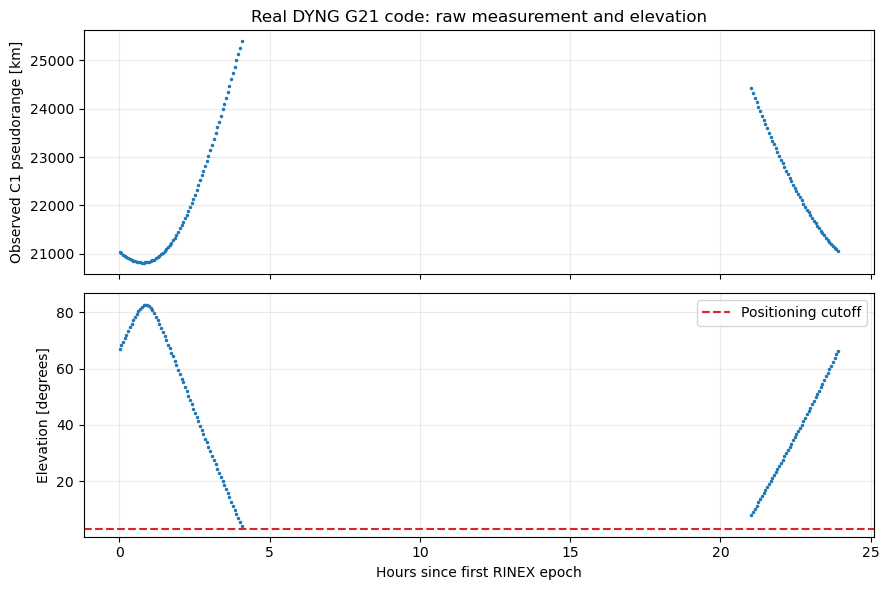

In [11]:
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(time_h, v('p1')*1e-3, '.', ms=3)
ax[0].set(ylabel='Observed C1 pseudorange [km]',
          title=f'Real DYNG {SAT} code: raw measurement and elevation')
ax[1].plot(time_h, el_deg, '.', ms=3)
ax[1].axhline(ELEVATION_CUTOFF_DEG, c='tab:red', ls='--', label='Positioning cutoff')
ax[1].set(xlabel='Hours since first RINEX epoch', ylabel='Elevation [degrees]')
for a in ax: a.grid(alpha=.25)
ax[1].legend()
plt.tight_layout()
plt.show()


## 3. Light travel time: where **was** G21 when it transmitted?

A pseudorange is received at $t_r$, but the satellite emitted the signal
earlier, at $t_{tx}=t_r-\tau$. The iteration in
`alg.sat_at_emission_time()` uses

$$\tau\simeq\frac{\|\mathbf r_s(t_{tx})-\mathbf r_r(t_r)\|}{c}.$$

The next plot shows the flight time in **milliseconds** and how much the
computed geometric range changes when we switch from same-epoch satellite
coordinates to emission-time coordinates. We keep the *same receiver
position* in both ranges. This is distinct from the Sagnac correction.

More detail: [signal travel time lesson](../light_travel_time/signal_travel_time_intro.ipynb).


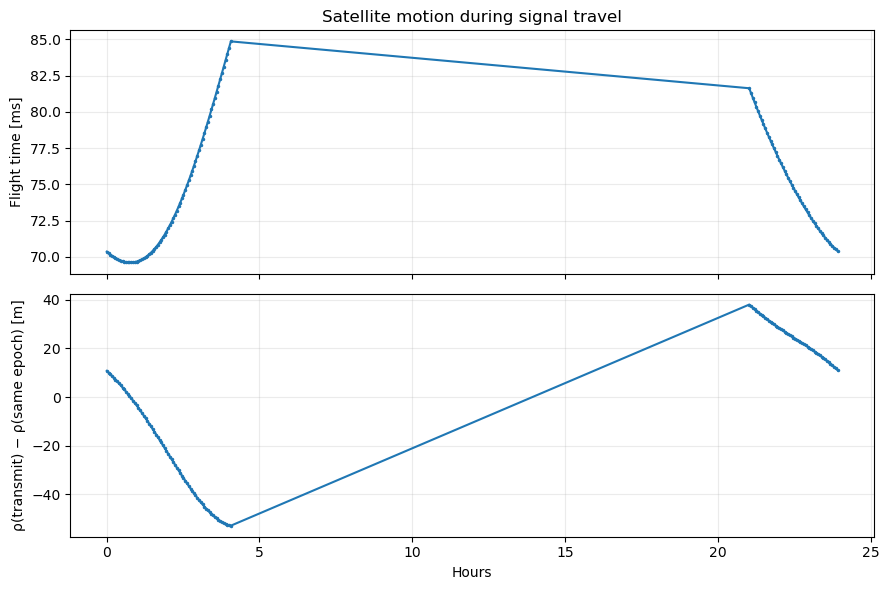

First real flight time [ms]: 70.3636
First emission-time geometric difference [m]: 10.7801


In [12]:
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(time_h, 1e3*v('tau'), '.-', ms=3)
ax[0].set(ylabel='Flight time [ms]', title='Satellite motion during signal travel')
ax[1].plot(time_h, v('light_time_m'), '.-', ms=3)
ax[1].set(xlabel='Hours', ylabel='ρ(transmit) − ρ(same epoch) [m]')
for a in ax: a.grid(alpha=.25)
plt.tight_layout()
plt.show()
assert np.allclose(gs.C*v('tau'), v('rho_tx'), atol=.002)
print('First real flight time [ms]:', round(1e3*v('tau')[0], 4))
print('First emission-time geometric difference [m]:', round(v('light_time_m')[0], 4))


## 4. Satellite clock: SP3 correction is **not** the receiver clock

The receiver observes a signal from a satellite whose clock is not exactly
system time. Our observation equation places the SP3 correction on the
**left**:

$$P_{IF}^{corr}+c\delta t_s=\rho+c\delta t_r+\cdots$$

`clock_s` from `sat_at_emission_time()` is in **seconds**; multiplication by
$c$ gives **metres of pseudorange**. The satellite clock correction can be
large compared with atmospheric and antenna effects. In contrast,
$\delta t_r$ is an *unknown*, estimated for each positioning epoch.


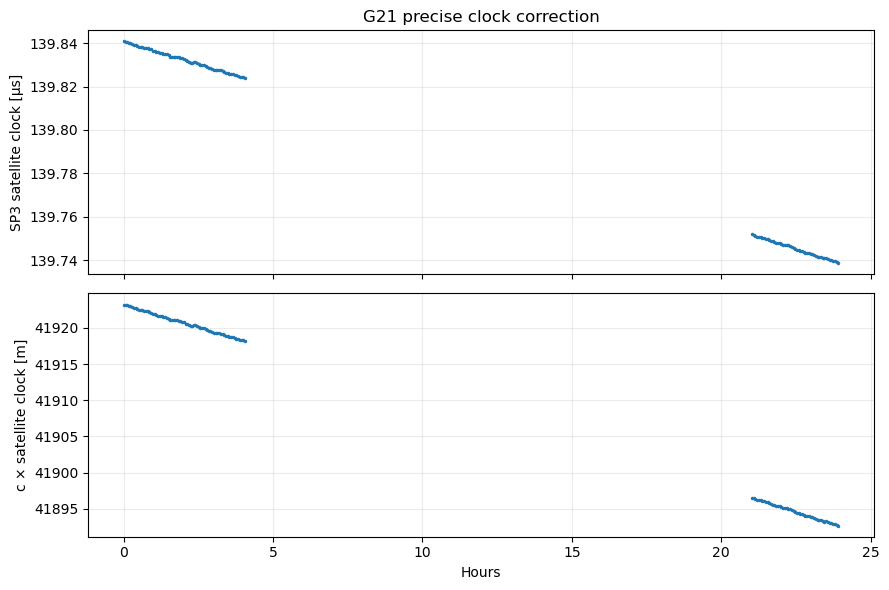

First satellite clock correction [m]: +41923.217


In [13]:
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(time_h, 1e6*v('clock_s'), '.', ms=3)
ax[0].set(ylabel='SP3 satellite clock [µs]', title='G21 precise clock correction')
ax[1].plot(time_h, gs.C*v('clock_s'), '.', ms=3)
ax[1].set(xlabel='Hours', ylabel='c × satellite clock [m]')
for a in ax: a.grid(alpha=.25)
plt.tight_layout()
plt.show()
print('First satellite clock correction [m]:', f'{gs.C*v("clock_s")[0]:+.3f}')


## 5. Earth rotation during signal travel: Sagnac term

The ECEF axes rotate during the signal flight. Our code applies the
first-order geometrical term separately:

$$\Delta\rho_{Sag}=\frac{\Omega_\oplus}{c}
\big(x_s(t_{tx})y_r(t_r)-y_s(t_{tx})x_r(t_r)\big).$$

It is **added to the computed range**, so it is *subtracted* when we form
an observation-minus-computation residual. Signs depend on the adopted
axes and equation; use `alg.sagnac_range_term()` with this notebook's
convention.


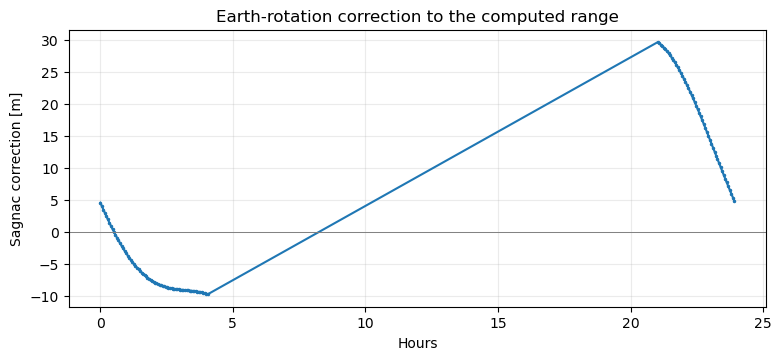

Sagnac correction at first epoch [m]: +4.510


In [17]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(time_h, v('sag'), '.-', ms=3)
ax.set(xlabel='Hours', ylabel='Sagnac correction [m]',
       title='Earth-rotation correction to the computed range')
ax.axhline(0, color='grey', lw=.7)
ax.grid(alpha=.25)
plt.show()
print('Sagnac correction at first epoch [m]:', f'{v("sag")[0]:+.3f}')

## 6. Relativistic satellite-clock eccentricity term

Satellite motion in Earth's gravitational field produces a periodic
relativistic clock effect. Our small GNSS API expresses the term in
**metres** for the *computed-side sign convention*:

$$\Delta\rho_{rel}=\frac{2\,\mathbf r_s\cdot\mathbf v_s}{c}.$$

`alg.relativistic_range_term()` evaluates the velocity near the satellite
**transmission epoch**. **Important:** precise SP3 clock product conventions
must be checked to avoid double-counting this effect.


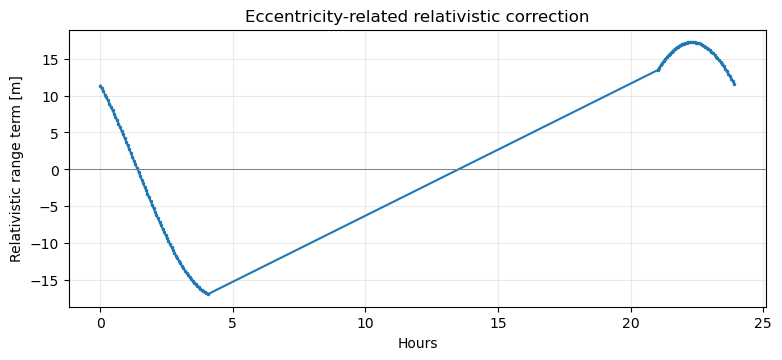

First relativistic range term [m]: +11.366


In [18]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(time_h, v('rel'), '.-', ms=3)
ax.axhline(0, color='grey', lw=.7)
ax.set(xlabel='Hours', ylabel='Relativistic range term [m]',
       title='Eccentricity-related relativistic correction')
ax.grid(alpha=.25)
plt.show()
print('First relativistic range term [m]:', f'{v("rel")[0]:+.3f}')


## 7. Ionosphere: cancel the first-order $1/f^2$ delay

GNSS *code* experiences a positive first-order ionospheric delay
$I(f)=40.3\,\mathrm{STEC}/f^2$. On two frequencies,

$$P_1=\rho+I_1+\cdots, \qquad P_2=\rho+I_2+\cdots$$

and the ionosphere-free (IF) combination is

$$P_{IF}=a_1P_1+a_2P_2, \quad
a_1=\frac{f_1^2}{f_1^2-f_2^2},\quad
a_2=-\frac{f_2^2}{f_1^2-f_2^2}.$$

The terms $a_1I_1+a_2I_2$ **cancel at first order**. We plot the real
L1/L2 code difference after correcting their OSBs. In practice
$P_2-P_1$ also contains measurement noise, multipath and higher-order
effects: it is an *ionospheric proxy*, not a direct truth measurement.

The IF combination **amplifies code noise**, because $|a_1|+|a_2|>1$.
More detail: [ionosphere lesson](../atmosphere/gnss_ionosphere_intro.ipynb).


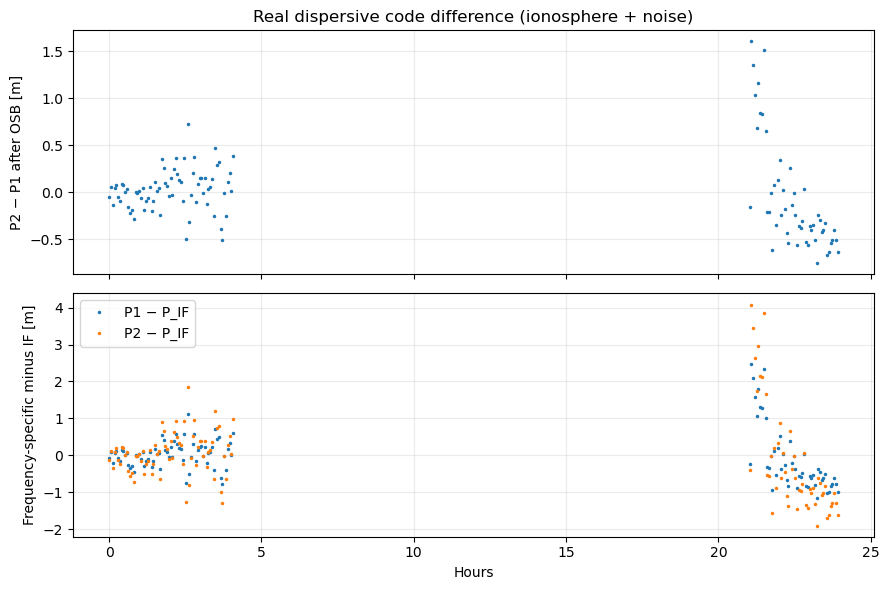

Noise amplification for equal, independent code uncertainties: ×2.978


In [19]:
p1_osb = v('p1')-v('b1')
p2_osb = v('p2')-v('b2')
iono1_proxy = p1_osb-v('pif_osb')
iono2_proxy = p2_osb-v('pif_osb')

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(time_h, p2_osb-p1_osb, '.', ms=3)
ax[0].set(ylabel='P2 − P1 after OSB [m]', title='Real dispersive code difference (ionosphere + noise)')
ax[1].plot(time_h, iono1_proxy, '.', ms=3, label='P1 − P_IF')
ax[1].plot(time_h, iono2_proxy, '.', ms=3, label='P2 − P_IF')
ax[1].set(xlabel='Hours', ylabel='Frequency-specific minus IF [m]')
ax[1].legend()
for a in ax: a.grid(alpha=.25)
plt.tight_layout()
plt.show()
print('Noise amplification for equal, independent code uncertainties:', f'×{np.sqrt(a1*a1+a2*a2):.3f}')
assert np.allclose(a1*iono1_proxy+a2*iono2_proxy, 0., atol=1e-7)


## 8. Satellite code hardware biases: OSB (Bias-SINEX)

Different code tracking descriptors have different equipment delays.
The daily Bias-SINEX **satellite code** OSBs in our positioning model follow

$$P_i^{OSB}=P_i^{raw}-b_i,\qquad
b_{IF}=a_1 b_1+a_2 b_2,\qquad
P_{IF}^{OSB}=P_{IF}^{raw}-b_{IF}.$$

`Bsinex.code_bias_m(PRN, signal, epoch)` returns **metres**, already
converted from the Bias-SINEX nanoseconds. In your data `C1C` and `C1W`
must not be assumed interchangeable. The bias product's satellite-clock
reference convention must match the precise clock product.

More detail: [Bias-SINEX lesson](../gnss_bias_intro/gnss_bias_sinex_intro.ipynb).


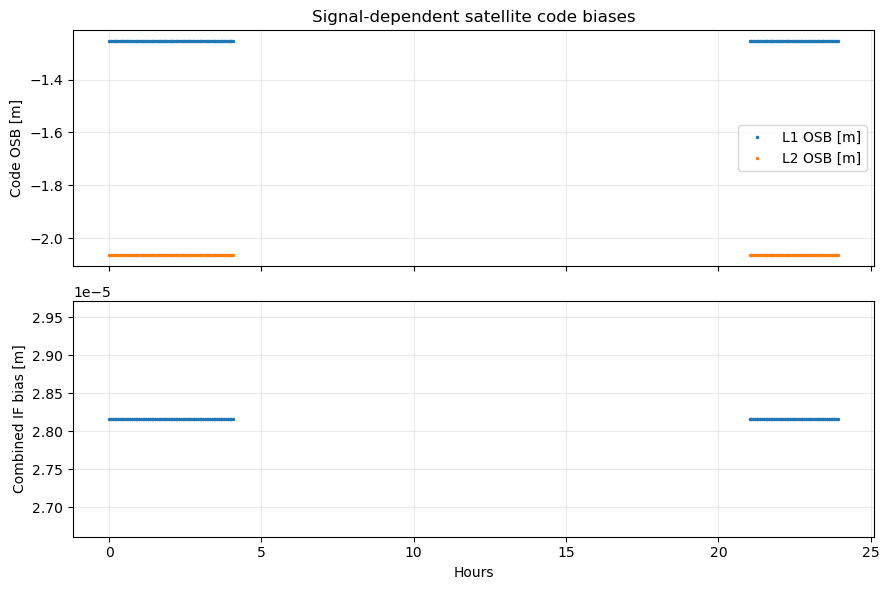

Observed code tracking pairs: {('C1W', 'C2W'): 123}
IF OSB correction at first epoch [m]: -0.000


In [20]:
bias_if = a1*v('b1')+a2*v('b2')
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(time_h, v('b1'), '.', ms=3, label='L1 OSB [m]')
ax[0].plot(time_h, v('b2'), '.', ms=3, label='L2 OSB [m]')
ax[0].legend()
ax[0].set(ylabel='Code OSB [m]', title='Signal-dependent satellite code biases')
ax[1].plot(time_h, bias_if, '.', ms=3)
ax[1].set(xlabel='Hours', ylabel='Combined IF bias [m]')
for a in ax: a.grid(alpha=.25)
plt.tight_layout()
plt.show()
assert np.allclose(v('pif_osb')-v('pif_raw'), -bias_if, atol=1e-7)
print('Observed code tracking pairs:', dict(Counter((row['code1'], row['code2']) for row in rows)))
print('IF OSB correction at first epoch [m]:', f'{-bias_if[0]:+.3f}')


## 9. Receiver antenna: PCO + PCV (ANTEX)

The receiver's signal phase centre generally differs from the antenna
reference point (ARP). An ANTEX calibration provides a **PCO vector** and
direction-dependent **PCV**. The course code models the NOAZI variation:

$$\Delta P_{rx,i} = \mathbf{PCO}_i^{NEU}\cdot
\begin{bmatrix}\cos E\cos Az\\\cos E\sin Az\\\sin E\end{bmatrix}
+PCV_i(E).$$

Notice the **NEU** PCO ordering, while the RINEX marker-to-ARP offset is
**H/E/N**, converted to ENU before ECEF. Mixing these orders gives a
plausible but wrong answer. The correction is **added to observed code**
to refer it to the ARP in this course convention.

More detail: [ANTEX lesson](../antex_intro/gnss_antex_antenna_intro.ipynb).


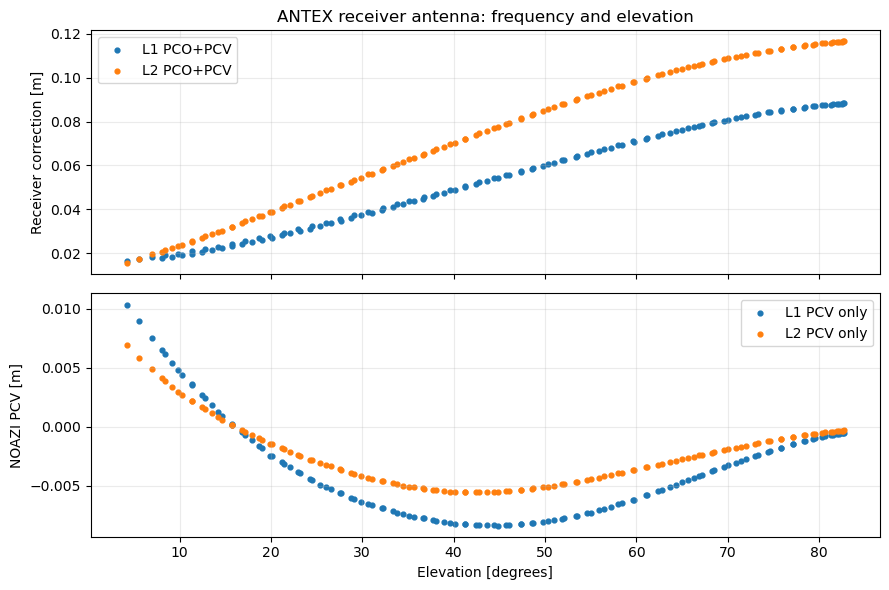

IF receiver antenna correction at first epoch [m]: +0.0350


In [22]:
los_neu = np.vstack((np.cos(v('el'))*np.cos(v('az')),
                     np.cos(v('el'))*np.sin(v('az')),
                     np.sin(v('el')))).T
rec_pco1 = los_neu @ rx_ant.pco('G01')
rec_pco2 = los_neu @ rx_ant.pco('G02')
rec_pcv1 = v('rec1')-rec_pco1
rec_pcv2 = v('rec2')-rec_pco2

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].scatter(el_deg, v('rec1'), s=12, label='L1 PCO+PCV')
ax[0].scatter(el_deg, v('rec2'), s=12, label='L2 PCO+PCV')
ax[0].set(ylabel='Receiver correction [m]',
          title='ANTEX receiver antenna: frequency and elevation')
ax[0].legend()
ax[1].scatter(el_deg, rec_pcv1, s=12, label='L1 PCV only')
ax[1].scatter(el_deg, rec_pcv2, s=12, label='L2 PCV only')
ax[1].set(xlabel='Elevation [degrees]', ylabel='NOAZI PCV [m]')
for a in ax: a.grid(alpha=.25)
ax[1].legend()
plt.tight_layout()
plt.show()
assert np.allclose(rec_pco1+rec_pcv1, v('rec1'))
print('IF receiver antenna correction at first epoch [m]:',
      f'{v("rec_if")[0]:+.4f}')


## 10. Satellite antenna: approximate nadir PCO (ANTEX)

SP3 positions are treated as satellite centres of mass (CoM). The actual
transmitting antenna has an offset. Following our intentionally **simple**
GNSS model, assume satellite body $+Z$ points towards Earth's centre and
use only the radial PCO:

$$\Delta P_{sat,i}\simeq PCO_{z,i}
\,\widehat{\mathbf r}_s\cdot
\widehat{(\mathbf r_s-\mathbf r_r)}.$$

The full 3D satellite attitude is **not** estimated. Body X/Y PCO and
satellite PCV are outside the scope of this lesson. As in the positioning
notebook, the approximate satellite correction is **added to code**.


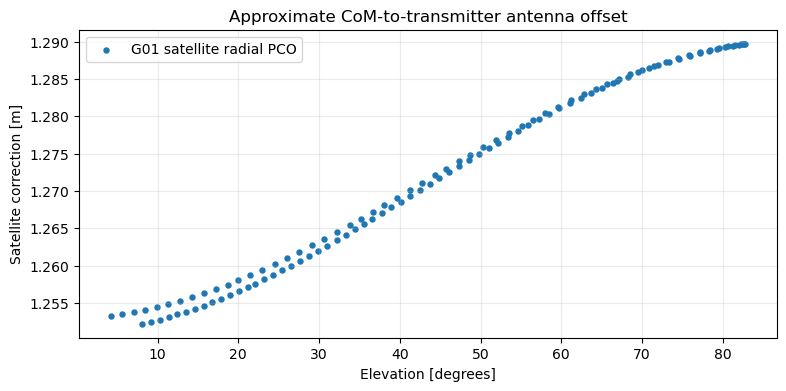

First total antenna code correction [m]: +1.3197


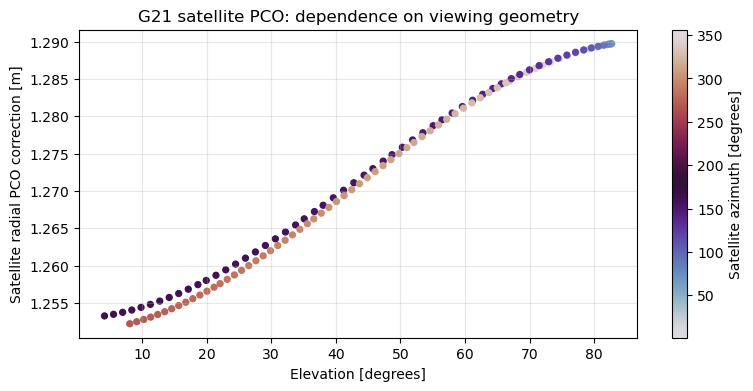

In [36]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(el_deg, v('sat1'), s=13, label='G01 satellite radial PCO')
# ax.scatter(el_deg, v('sat2'), s=13, label='G02 satellite radial PCO')
# ax.scatter(el_deg, v('sat_if'), s=13, label='IF combination')
ax.set(xlabel='Elevation [degrees]', ylabel='Satellite correction [m]',
       title='Approximate CoM-to-transmitter antenna offset')
ax.legend()
ax.grid(alpha=.25)
plt.show()
assert np.allclose(v('pif_final')-v('pif_osb'),v('rec_if')+v('sat_if'), atol=1e-7)
print('First total antenna code correction [m]:', f'{v("rec_if")[0]+v("sat_if")[0]:+.4f}')

fig, ax = plt.subplots(figsize=(9, 4))
sc = ax.scatter(el_deg, v('sat1'), c=np.rad2deg(v('az')) % 360, cmap='twilight', s=18)
fig.colorbar(sc, ax=ax, label='Satellite azimuth [degrees]')
ax.set(
    xlabel='Elevation [degrees]',
    ylabel='Satellite radial PCO correction [m]',
    title='G21 satellite PCO: dependence on viewing geometry'
)
ax.grid(alpha=0.3)
plt.show()

## 11. Ground marker → antenna reference point (ARP)

The RINEX header contains the marker-to-ARP eccentricity in **height,
east and north**. Its ECEF displacement changes the modeled satellite range:

$$\Delta\rho_{ARP}=
\|\mathbf r_s-(\mathbf r_{marker}+\mathbf d_{ARP})\|
-\|\mathbf r_s-\mathbf r_{marker}\|.$$

This is a **geometrical reference-point change**, not the ANTEX PCO
correction above. The positioning solver estimates the marker coordinates
but predicts signal propagation to the displaced antenna. A one-metre
station-coordinate error can produce nearly a one-metre line-of-sight
range error, motivating the XYZ estimation.


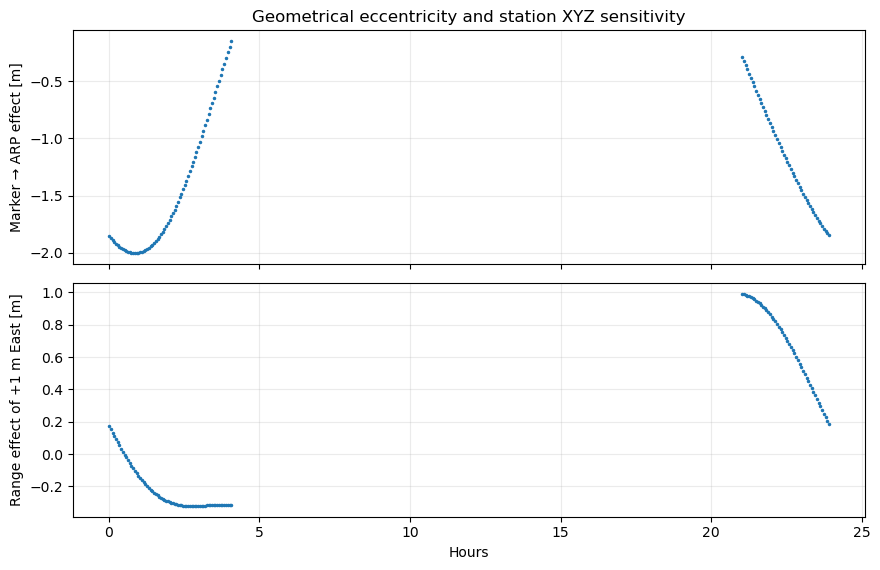

RINEX marker → ARP ECEF offset [m]: [1.45192864 0.64438977 1.24458388]


In [34]:
fig, ax = plt.subplots(2, 1, figsize=(9, 5.8), sharex=True)
ax[0].plot(time_h, v('offset_arp_range'), '.', ms=3)
ax[0].set(ylabel='Marker → ARP effect [m]', title='Geometrical eccentricity and station XYZ sensitivity')
# For a hypothetical +1 m East marker error: -u·delta_station is the
# first-order range change. Use the real azimuth/elevation at each epoch.
east_sensitivity = -np.cos(v('el'))*np.sin(v('az'))
ax[1].plot(time_h, east_sensitivity, '.', ms=3)
ax[1].set(xlabel='Hours', ylabel='Range effect of +1 m East [m]')
for a in ax: a.grid(alpha=.25)
plt.tight_layout()
plt.show()
print('RINEX marker → ARP ECEF offset [m]:', offset_arp)
# assert np.all(np.abs(v('offset_arp_range')) <= np.linalg.norm(offset_arp)+1e-6)


## 12. Solid Earth tides: the ground itself moves (pyTMD)

At a given epoch, tidal gravity from the Sun and Moon displaces the
**ground marker**. We use `solid_earth_tide_xyz(marker_xyz, t, rinex_scale)`
to obtain an approximate ECEF displacement, then update the receiver
position before computing the line-of-sight range:

$$\mathbf r_r(t)=\mathbf r_{marker}+\mathbf d_{ARP}
+\mathbf d_{SET}(t).$$

The observed *range impact* is a projection of the displacement; it is
generally smaller than the norm of the 3D station displacement. This
simple API uses Astropy/pyTMD.


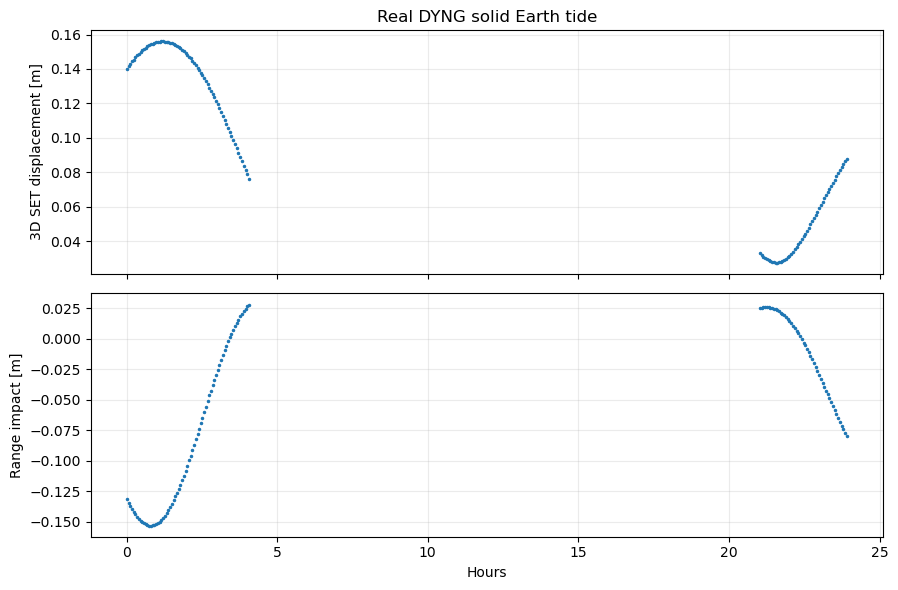

First tidal displacement vector [m]: [0.0747079  0.0539429  0.10555104]


In [35]:
tidal_xyz = np.vstack([row['tide_xyz'] for row in rows])
tide_mag = np.linalg.norm(tidal_xyz, axis=1)
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(time_h, tide_mag, '.', ms=3)
ax[0].set(ylabel='3D SET displacement [m]', title='Real DYNG solid Earth tide')
ax[1].plot(time_h, v('tide_range'), '.', ms=3)
ax[1].set(xlabel='Hours', ylabel='Range impact [m]')
for a in ax: a.grid(alpha=.25)
plt.tight_layout()
plt.show()
assert np.all(np.abs(v('tide_range')) <= tide_mag+1e-6)
print('First tidal displacement vector [m]:', tidal_xyz[0])


## 13. Neutral atmosphere: hydrostatic + wet delay (VMF3)

Unlike first-order ionosphere, the neutral-atmosphere delay **does not
cancel** in the ionosphere-free combination. The model separates

$$T(E,t)=\underbrace{ZHD(t)\,m_h(E,t)}_{T_{dry}}
+\underbrace{ZWD(t)\,m_w(E,t)}_{T_{wet}}.$$

Here VMF3 provides the $ZHD$, an **a priori** $ZWD$, and elevation-/epoch-
dependent hydrostatic and wet mapping factors. In actual code positioning
the $ZHD$ is modeled while **ZWD(t) is estimated as piecewise-linear
parameters**. The VMF3 wet value plotted below is a model reference,
**not** the final estimated ZWD.

More detail: [troposphere lesson](../atmosphere/gnss_tropospheric_delay_intro.ipynb).


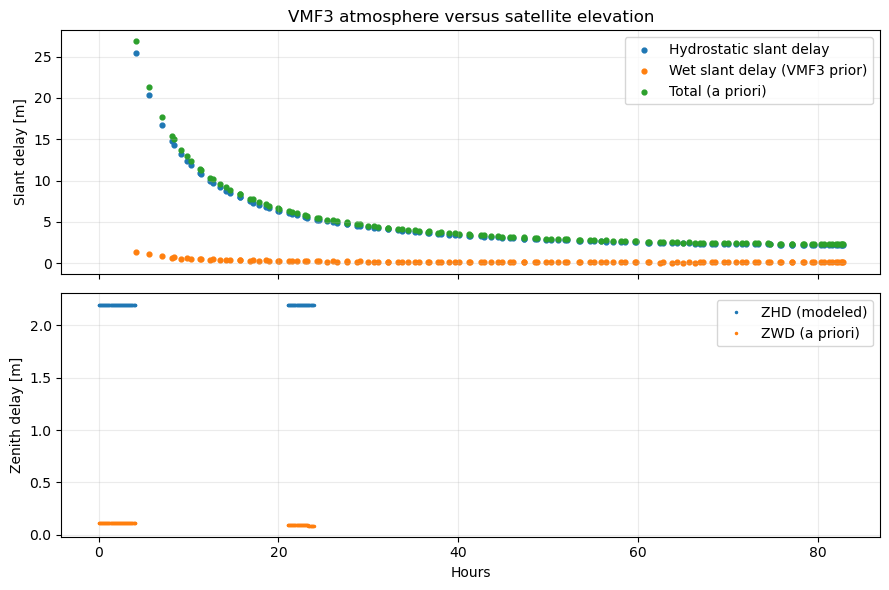

First real epoch: dry and wet slant delays [m]: 2.3890 0.1223


In [37]:
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].scatter(el_deg, v('dry'), s=12, label='Hydrostatic slant delay')
ax[0].scatter(el_deg, v('wet'), s=12, label='Wet slant delay (VMF3 prior)')
ax[0].scatter(el_deg, v('dry')+v('wet'), s=12, label='Total (a priori)')
ax[0].set(ylabel='Slant delay [m]', title='VMF3 atmosphere versus satellite elevation')
ax[0].legend()
ax[1].plot(time_h, v('zhd'), '.', ms=3, label='ZHD (modeled)')
ax[1].plot(time_h, v('zwd_prior'), '.', ms=3, label='ZWD (a priori)')
ax[1].set(xlabel='Hours', ylabel='Zenith delay [m]')
for a in ax: a.grid(alpha=.25)
ax[1].legend()
plt.tight_layout()
plt.show()
assert np.all(v('dry') > 0) and np.all(v('wet') >= 0)
print('First real epoch: dry and wet slant delays [m]:',
      f'{v("dry")[0]:.4f}', f'{v("wet")[0]:.4f}')


## 14. Estimated parameters: receiver clock and piecewise ZWD

There are two quantities that the code-positioning notebook does **not**
know from correction products:

1. $c\delta t_r(t_k)$ — a different receiver-clock **range** parameter at
   every observation epoch;
2. $ZWD(t)$ — zenith wet delay, interpolated between **two-hour knots**:

$$ZWD(t)=(1-\alpha)\,ZWD_k+\alpha\,ZWD_{k+1}, \quad 0\le\alpha\le 1.$$

The wet-delay contribution to one observation is $m_w(E,t)ZWD(t)$.
For example, an additional **1 cm** of zenith wet delay produces
$0.01\,m_w$ metres in a slant code observation. It is *not* valid to
subtract the VMF3 a priori wet delay as though it were an independently
known true correction and then also estimate ZWD.


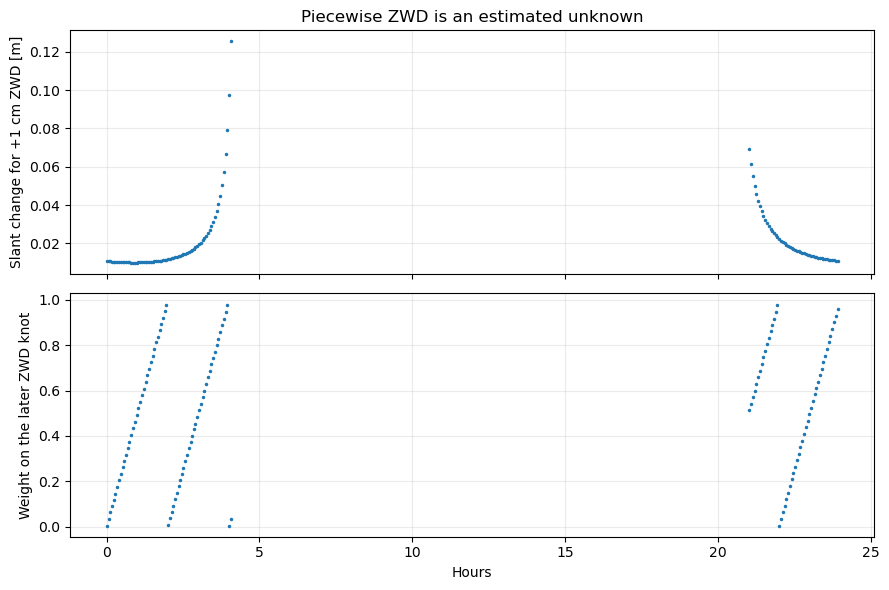

First row interpolation: knot 0 weight 0.996, knot 1 weight 0.004


In [38]:
zwd_knot_hours = 2.0
knot_number = np.floor(time_h / zwd_knot_hours).astype(int)
alpha = (time_h/zwd_knot_hours)-knot_number
assert np.all((alpha >= 0.) & (alpha < 1.+1e-10))

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(time_h, .01*v('mw'), '.', ms=3)
ax[0].set(ylabel='Slant change for +1 cm ZWD [m]',
          title='Piecewise ZWD is an estimated unknown')
ax[1].plot(time_h, alpha, '.', ms=3)
ax[1].set(xlabel='Hours', ylabel='Weight on the later ZWD knot')
for a in ax: a.grid(alpha=.25)
plt.tight_layout()
plt.show()
print('First row interpolation:',
      f'knot {knot_number[0]} weight {1-alpha[0]:.3f}, '
      f'knot {knot_number[0]+1} weight {alpha[0]:.3f}')


## 15. From modeled pseudorange to a **clock-contaminated misclosure**

Bring the known terms to one side of the observation equation:

$$
\underbrace{P_{IF}^{corr}+c\delta t_s-
\rho(t_{tx})-\Delta\rho_{Sag}-\Delta\rho_{rel}
-ZHD\,m_h-ZWD_{prior}\,m_w}_{\text{one-satellite misclosure}}
\approx c\delta t_r+\epsilon_{\rm remaining}.
$$

Below we show a simple **before/after** sequence, beginning with raw IF
code relative to the *same-epoch* SP3 range, then adding the propagation,
instrumental, and atmospheric models. To compare the shapes, we subtract
the median of each curve. Crucially, these are **not post-fit residuals**:
the receiver-clock function, estimated XYZ and piecewise ZWD have not been
solved. A real residual RMS is available only after multi-satellite least
squares in `beta/gps_code_positioning.ipynb`.


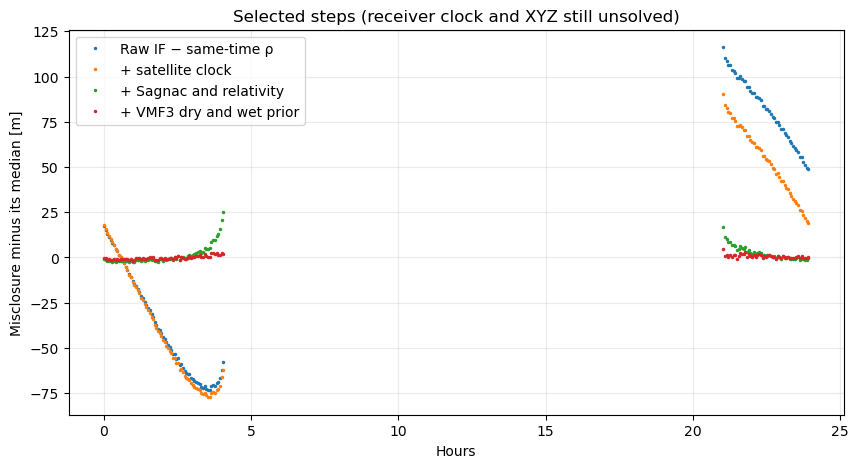

First epoch: modeled correction changes, relative to raw IF:
  + satellite clock              +41923.2170 m
  + emission-time geometry          -10.7801 m
  + Sagnac and relativity           -15.8760 m
  + code OSBs                        -0.0000 m
  + antenna corrections              +1.3197 m
  + VMF3 dry and wet prior           -2.5113 m
First final misclosure [m] (NOT a true receiver clock): -7105.1547


In [39]:
rho0 = v('rho_rx')
clock_range = gs.C*v('clock_s')
raw_if = v('pif_raw')

# Each stage holds exactly the same rows and orbit/range conventions.
stage_0 = raw_if-rho0
stage_1 = raw_if+clock_range-rho0
stage_2 = raw_if+clock_range-v('rho_tx')
stage_3 = stage_2-v('sag')-v('rel')
stage_4 = v('pif_osb')+clock_range-v('rho_tx')-v('sag')-v('rel')
stage_5 = v('pif_final')+clock_range-v('rho_tx')-v('sag')-v('rel')
stage_6 = stage_5-v('dry')-v('wet')

assert np.allclose(stage_6, v('closure_after'), atol=1e-7)
stages = [stage_0, stage_1, stage_2, stage_3,
          stage_4, stage_5, stage_6]
names = ['Raw IF − same-time ρ', '+ satellite clock',
         '+ emission-time geometry', '+ Sagnac and relativity',
         '+ code OSBs', '+ antenna corrections',
         '+ VMF3 dry and wet prior']

fig, ax = plt.subplots(figsize=(10, 5))
for k in (0, 1, 3, 6):
    centered = stages[k]-np.median(stages[k])
    ax.plot(time_h, centered, '.', ms=3, label=names[k])
ax.set(xlabel='Hours', ylabel='Misclosure minus its median [m]',
       title='Selected steps (receiver clock and XYZ still unsolved)')
ax.grid(alpha=.25)
ax.legend()
plt.show()

print('First epoch: modeled correction changes, relative to raw IF:')
for name, previous, current in zip(names[1:], stages[:-1], stages[1:]):
    print(f'  {name:<30s} {current[0]-previous[0]:+11.4f} m')
print('First final misclosure [m] (NOT a true receiver clock):',
      f'{stage_6[0]:+.4f}')


## 16. Which effects are large? A real-data **magnitude** budget

This compares the median **absolute size of the modeled terms** across the
selected real G21 epochs. It is **not an accuracy ranking**: a large clock
correction can be very precise, whereas a much smaller multipath residual
may be unpredictable. Some entries modify the *observed code*, others the
*computed range*; they should not be blindly added with the same sign.

Notice how very different the scales can be (logarithmic horizontal axis).
The precise satellite orbit and clock products have their own errors, but
we do not estimate those product errors from this single-station example.


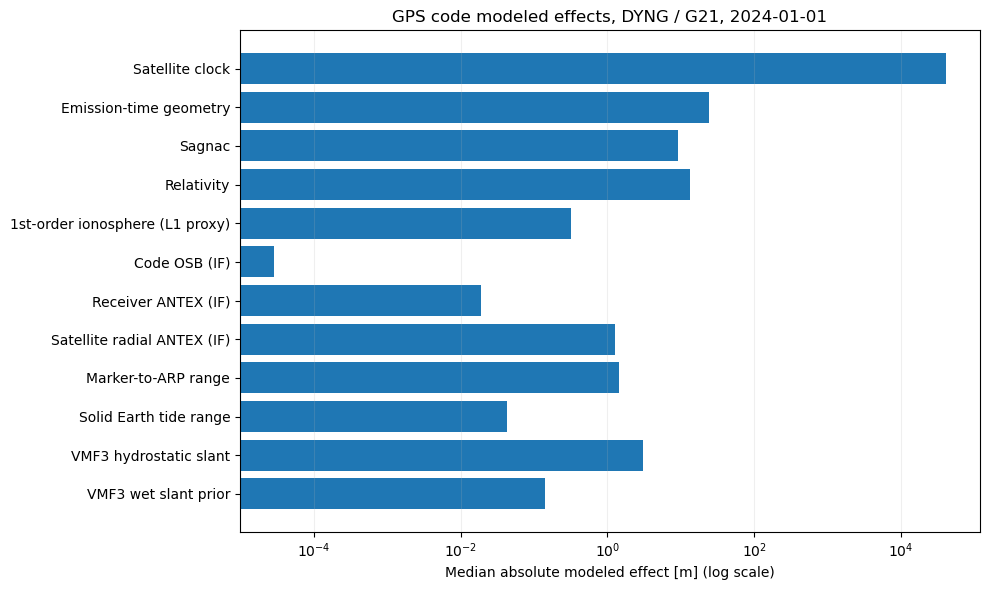

Model term                          Median |value| [m]
----------------------------------------------------------
Satellite clock                           41918.8233
Emission-time geometry                       24.4560
Sagnac                                        9.0807
Relativity                                   13.4317
1st-order ionosphere (L1 proxy)               0.3219
Code OSB (IF)                                 0.0000
Receiver ANTEX (IF)                           0.0188
Satellite radial ANTEX (IF)                   1.2721
Marker-to-ARP range                           1.4241
Solid Earth tide range                        0.0424
VMF3 hydrostatic slant                        3.1055
VMF3 wet slant prior                          0.1415


In [40]:
effects = [
    ('Satellite clock', clock_range),
    ('Emission-time geometry', v('light_time_m')),
    ('Sagnac', v('sag')),
    ('Relativity', v('rel')),
    ('1st-order ionosphere (L1 proxy)', iono1_proxy),
    ('Code OSB (IF)', bias_if),
    ('Receiver ANTEX (IF)', v('rec_if')),
    ('Satellite radial ANTEX (IF)', v('sat_if')),
    ('Marker-to-ARP range', v('offset_arp_range')),
    ('Solid Earth tide range', v('tide_range')),
    ('VMF3 hydrostatic slant', v('dry')),
    ('VMF3 wet slant prior', v('wet')),
]
labels = [name for name, _ in effects]
sizes = [float(np.median(np.abs(vals))) for _, vals in effects]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(labels[::-1], np.maximum(sizes[::-1], 1e-5))
ax.set_xscale('log')
ax.set(xlabel='Median absolute modeled effect [m] (log scale)',
       title=f'GPS code modeled effects, DYNG / {SAT}, 2024-01-01')
ax.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()

print('Model term                          Median |value| [m]')
print('-'*58)
for label, amount in effects:
    print(f'{label:<40s} {np.median(np.abs(amount)):11.4f}')


## 17. Observation noise, elevation and the positioning exercise

In addition to the modeled terms, code observations contain **multipath,
thermal noise, local interference, unmodeled hardware effects and residual
product errors**. No deterministic correction above removes all of them.

For the classroom solution, the assumed code standard deviation is

$$\sigma_P(E)=\frac{5\ \mathrm m}{\sin E},\qquad
w(E)=\frac{1}{\sigma_P(E)^2}.$$

This is a *weighting model*, **not a direct measurement of precision**.
Low-elevation observations are down-weighted, and the 3° elevation cutoff
helps avoid especially difficult geometries and multipath.

We are now ready to use these modeled quantities in a **multi-satellite
code-only least-squares solution**. That subsequent step estimates marker
$X,Y,Z$, epoch receiver clocks and two-hour ZWD knots, then gives true
*post-fit residuals* for analysis. SINEX provides an independent coordinate
comparison, not an input correction to the code pseudorange itself.

**Next notebooks:**
[`beta/gps_code_positioning.ipynb`](beta/gps_code_positioning.ipynb) ·
[`gnss_sinex_coordinates_intro.ipynb`](../sinex_intro/gnss_sinex_coordinates_intro.ipynb).


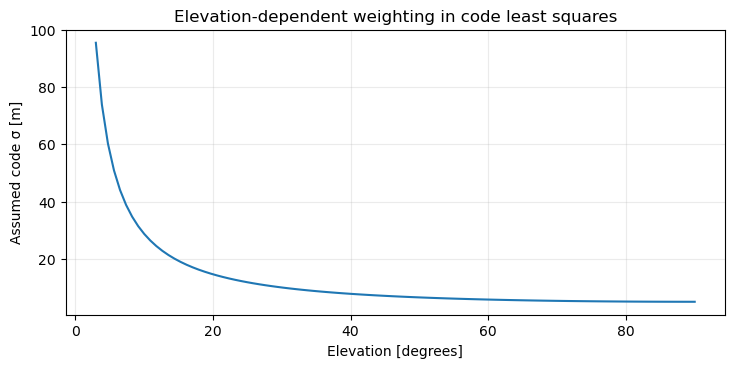

At elevation 90°: σ = 5.0 m; at 10°: σ = 28.79 m


In [41]:
elevations = np.linspace(3., 90., 100)
sigma_model = 5. / np.sin(np.deg2rad(elevations))
fig, ax = plt.subplots(figsize=(8.5, 3.7))
ax.plot(elevations, sigma_model)
ax.set(xlabel='Elevation [degrees]', ylabel='Assumed code σ [m]',
       title='Elevation-dependent weighting in code least squares')
ax.grid(alpha=.25)
plt.show()
print('At elevation 90°: σ = 5.0 m; at 10°: σ =',
      f'{5./np.sin(np.deg2rad(10)):.2f} m')
